In [1]:
%pip -q install "datasets>=3,<5" "transformers>=4.45,<5" \
    "huggingface_hub>=0.26,<1" "Pillow>=10" \
    scikit-learn pandas matplotlib seaborn joblib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
from pathlib import Path
import copy
import hashlib
import html
import json
import random
import re
import subprocess
import time
import unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

from datasets import load_dataset
from huggingface_hub import HfApi
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer

from google.colab import drive
drive.mount("/content/drive")

# First run: True. Final experiments: False.
SMOKE_TEST = False

ROOT = Path("/content/drive/MyDrive/CrisisMMD_Project")
OUT = ROOT / ("smoke" if SMOKE_TEST else "full")
OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [42]
MAX_EPOCHS = 15
PATIENCE = 4
DEVICE = torch.device("cpu")



def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

set_seed(42)

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name())

print("Mode:", "SMOKE TEST" if SMOKE_TEST else "FULL EXPERIMENT")
print("Output folder:", OUT)

# Record the actual installed versions for reproducibility.
(OUT / "environment.txt").write_text(
    subprocess.check_output(["pip", "freeze"], text=True)
)

Mounted at /content/drive
Device: cpu
Mode: FULL EXPERIMENT
Output folder: /content/drive/MyDrive/CrisisMMD_Project/full


14161

In [3]:
from datasets import load_dataset
from huggingface_hub import HfApi

api = HfApi()
revision_file = ROOT / "source_revisions.json"

if revision_file.exists():
    revisions = json.loads(revision_file.read_text())
else:
    revisions = {
        "dataset": api.dataset_info(
            "QCRI/CrisisMMD",
            revision="refs/convert/parquet",
        ).sha,
        "text_encoder": api.model_info(
            "distilbert/distilbert-base-uncased"
        ).sha,
    }

    revision_file.write_text(
        json.dumps(revisions, indent=2)
    )

# Discover actual files rather than relying on configuration names.
repo_files = api.list_repo_files(
    repo_id="QCRI/CrisisMMD",
    repo_type="dataset",
    revision=revisions["dataset"],
)

data_files = {}

for split in ["train", "dev", "test"]:
    matching_files = sorted(
        path
        for path in repo_files
        if path.startswith(f"informative/{split}/")
        and path.endswith(".parquet")
    )

    if not matching_files:
        available_parquet = [
            path for path in repo_files
            if path.endswith(".parquet")
        ]

        raise ValueError(
            f"No informative files found for {split}. "
            f"Available Parquet paths: {available_parquet[:30]}"
        )

    data_files[split] = [
        (
            "hf://datasets/QCRI/CrisisMMD"
            f"@{revisions['dataset']}/{path}"
        )
        for path in matching_files
    ]

    print(f"{split}: {len(matching_files)} Parquet file(s)")

dataset = load_dataset(
    "parquet",
    data_files=data_files,
)

assert {"train", "dev", "test"}.issubset(dataset.keys())

label_feature = dataset["train"].features["label"]

if not hasattr(label_feature, "names"):
    raise ValueError(
        "Expected named class labels. "
        f"Actual features: {dataset['train'].features}"
    )

label_names = label_feature.names

assert set(label_names) == {
    "informative",
    "not_informative",
}, label_names

print(dataset)
print("Original label names:", label_names)
print("Our mapping: not_informative = 0, informative = 1")

train: 1 Parquet file(s)
dev: 1 Parquet file(s)
test: 1 Parquet file(s)


informative/train/0000.parquet:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

informative/dev/0000.parquet:   0%|          | 0.00/417k [00:00<?, ?B/s]

informative/test/0000.parquet:   0%|          | 0.00/417k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating dev split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 13608
    })
    dev: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 2237
    })
    test: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 2237
    })
})
Original label names: ['informative', 'not_informative']
Our mapping: not_informative = 0, informative = 1


In [4]:
from google.colab import userdata
from huggingface_hub import login

login(
    token=userdata.get("HF_TOKEN"),
    add_to_git_credential=False,
)

print("Hugging Face authentication configured.")

Hugging Face authentication configured.


This may take several minutes on the first run.


Fetching 18082 files:   0%|          | 0/18082 [00:00<?, ?it/s]


Images connected successfully.
First image size: (640, 480)
First image mode: RGB


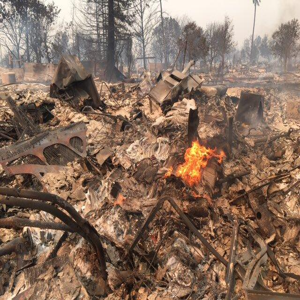

In [6]:
from pathlib import Path
from PIL import Image as PILImage
from datasets import Image as DatasetImage
from huggingface_hub import HfApi, snapshot_download

api = HfApi()

# Pin the original image repository revision for reproducibility.
if "image_source" not in revisions:
    revisions["image_source"] = api.dataset_info(
        "QCRI/CrisisMMD",
        revision="main",
    ).sha

    revision_file.write_text(
        json.dumps(revisions, indent=2)
    )

print("Downloading original images.")
print("This may take several minutes on the first run.")

image_folder = snapshot_download(
    repo_id="QCRI/CrisisMMD",
    repo_type="dataset",
    revision=revisions["image_source"],
    allow_patterns=["data_image/**"],
    local_dir=str(ROOT / "original_images"),
    max_workers=1,
    token=userdata.get("HF_TOKEN"),
)

image_folder = Path(image_folder)

# Resolve and verify every referenced image path first.
resolved_paths = {}
missing_paths = []

for split in ["train", "dev", "test"]:
    paths = []

    for relative_path in dataset[split]["image_path"]:
        relative_path = str(relative_path).replace("\\", "/")

        # Use the repository-relative data_image path.
        if "data_image/" not in relative_path:
            raise ValueError(
                f"Unexpected image path: {relative_path}"
            )

        relative_path = (
            "data_image/"
            + relative_path.split("data_image/", 1)[1]
        )

        local_path = image_folder / relative_path

        if not local_path.is_file():
            missing_paths.append(str(local_path))

        paths.append(str(local_path))

    resolved_paths[split] = paths

if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} referenced images are missing. "
        f"Examples: {missing_paths[:5]}"
    )

# Replace the empty image column with actual local image paths.
for split in ["train", "dev", "test"]:
    repaired_split = dataset[split].remove_columns("image")

    repaired_split = repaired_split.add_column(
        "image",
        resolved_paths[split],
    )

    dataset[split] = repaired_split.cast_column(
        "image",
        DatasetImage(),
    )

# Fail immediately if decoding still does not work.
sample = dataset["train"][0]
image = sample["image"]

assert isinstance(image, PILImage.Image), (
    f"Expected a PIL image, received {type(image)}"
)

print("\nImages connected successfully.")
print("First image size:", image.size)
print("First image mode:", image.mode)

display(image.copy().resize((300, 300)))

In [7]:
split_caps = {"train": 1200, "dev": 300, "test": 300}
split_priority = {"train": 0, "dev": 1, "test": 2}

# Catch an incomplete image setup before scanning the subset.
if dataset["train"][0]["image"] is None:
    raise RuntimeError(
        "The image column is empty. Run the image reconnection cell first."
    )


def clean_text(text):
    text = unicodedata.normalize("NFKC", html.unescape(text))
    text = re.sub(r"https?://\S+", " url ", text)
    text = re.sub(r"@\w+", " user ", text)
    return re.sub(r"\s+", " ", text).strip()


rows = []
failures = []
sampled_counts = {}

for split, cap in split_caps.items():
    split_data = dataset[split]
    source_indices = np.arange(len(split_data))

    if len(source_indices) > cap:
        source_indices, _ = train_test_split(
            source_indices,
            train_size=cap,
            stratify=np.asarray(split_data["label"]),
            random_state=42,
        )

    sampled_counts[split] = len(source_indices)

    for source_idx in tqdm(sorted(source_indices), desc=f"Checking {split}"):
        source_idx = int(source_idx)

        try:
            record = split_data[source_idx]
            raw_text = record["tweet_text"]

            if not isinstance(raw_text, str) or not raw_text.strip():
                raise ValueError("Missing or empty text")

            if record["image"] is None:
                raise ValueError("Missing image")

            image = record["image"].convert("RGB")
            text = clean_text(raw_text)

            rows.append({
                "split": split,
                "source_idx": source_idx,
                "text": text,
                "text_hash": hashlib.sha256(
                    text.casefold().encode()
                ).hexdigest(),
                "image_hash": hashlib.sha256(
                    str(image.size).encode() + image.tobytes()
                ).hexdigest(),
                "tweet_id": record["tweet_id"],
                "event": record["event_name"],
                "y": int(label_names[int(record["label"])] == "informative"),
                "width": image.width,
                "height": image.height,
                "word_count": len(text.split()),
            })

        except (OSError, ValueError) as error:
            failures.append({
                "split": split,
                "source_idx": source_idx,
                "error": str(error),
            })

failure_table = pd.DataFrame(
    failures, columns=["split", "source_idx", "error"]
)
failure_table.to_csv(OUT / "audit_failures.csv", index=False)

metadata = pd.DataFrame(rows)

if metadata.empty:
    raise RuntimeError(
        f"No records passed the audit. First failures: {failures[:3]}"
    )

# Group rows connected by a shared tweet ID, text hash or image hash.
parent = list(range(len(metadata)))


def find_root(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index


for column in ["tweet_id", "text_hash", "image_hash"]:
    first_seen = {}

    for index, value in enumerate(metadata[column]):
        if pd.isna(value) or not str(value).strip():
            continue

        if value in first_seen:
            parent[find_root(index)] = find_root(first_seen[value])
        else:
            first_seen[value] = index

metadata["group"] = [find_root(index) for index in range(len(metadata))]

# Keep test rows first, then dev, then train within each duplicate group.
metadata["priority"] = metadata["split"].map(split_priority)
highest_priority = metadata.groupby("group")["priority"].transform("max")
metadata["keep"] = metadata["priority"].eq(highest_priority)

work = metadata.loc[metadata["keep"]].reset_index(drop=True)

if work.groupby("group")["split"].nunique().gt(1).any():
    raise RuntimeError("A duplicate group still crosses retained splits.")

quality_summary = (
    metadata.groupby("split")
    .agg(
        valid_records=("y", "size"),
        informative_rate=("y", "mean"),
        average_words=("word_count", "mean"),
        repeated_text_rows=("text_hash", lambda s: s.duplicated().sum()),
        repeated_image_rows=("image_hash", lambda s: s.duplicated().sum()),
        retained_records=("keep", "sum"),
    )
    .reindex(split_caps)
)

quality_summary.insert(0, "sampled_records", pd.Series(sampled_counts))
for column in ["valid_records", "retained_records"]:
    quality_summary[column] = quality_summary[column].fillna(0).astype(int)

quality_summary["audit_failures"] = (
    quality_summary["sampled_records"] - quality_summary["valid_records"]
)
quality_summary["removed_for_overlap"] = (
    quality_summary["valid_records"] - quality_summary["retained_records"]
)

quality_summary.to_csv(OUT / "data_quality.csv")
pd.crosstab(work["event"], work["split"]).to_csv(
    OUT / "retained_event_counts.csv"
)

display(quality_summary)

for split in split_caps:
    if work.loc[work["split"].eq(split), "y"].nunique() != 2:
        raise RuntimeError(
            f"{split} must retain both classes. Check the audit summary above."
        )

print("Retained records by split and class (1 = informative)")
display(pd.crosstab(work["split"], work["y"]))

Checking train:   0%|          | 0/1200 [00:00<?, ?it/s]

Checking dev:   0%|          | 0/300 [00:00<?, ?it/s]

Checking test:   0%|          | 0/300 [00:00<?, ?it/s]

,sampled_records,valid_records,informative_rate,average_words,repeated_text_rows,repeated_image_rows,retained_records,audit_failures,removed_for_overlap
split,,,,,,,,,
train,1200,1200,0.613333,14.100000,15,2,1200,0,0
dev,300,300,0.630000,13.946667,0,0,300,0,0
test,300,300,0.613333,14.080000,0,1,300,0,0


Retained records by split and class (1 = informative)


y,0,1
split,,
dev,111,189
test,116,184
train,464,736


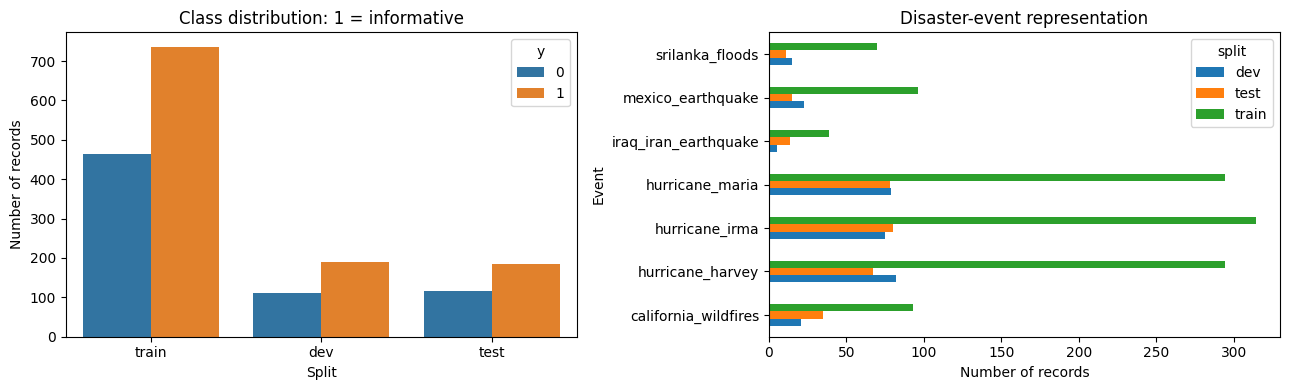

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(
    data=work,
    x="split",
    hue="y",
    ax=axes[0],
)

axes[0].set_title("Class distribution: 1 = informative")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Number of records")

pd.crosstab(
    work["event"], work["split"]
).plot.barh(ax=axes[1])

axes[1].set_title("Disaster-event representation")
axes[1].set_xlabel("Number of records")
axes[1].set_ylabel("Event")

plt.tight_layout()
plt.savefig(
    OUT / "data_distribution.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

train_mask = work["split"].eq("train")
train_text = work.loc[train_mask, "text"]

# Fit the vocabulary and dimensionality reduction on training text only.
started = time.perf_counter()

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=6000,
    sublinear_tf=True,
)

train_tfidf = vectorizer.fit_transform(train_text)
n_components = min(96, train_tfidf.shape[0] - 1, train_tfidf.shape[1] - 1)

if n_components < 2:
    raise ValueError("Too few training records or text features after the audit.")

reducer = TruncatedSVD(n_components=n_components, random_state=42)
reducer.fit(train_tfidf)

all_tfidf = vectorizer.transform(work["text"])
text_embeddings = reducer.transform(all_tfidf).astype("float32")
text_seconds = time.perf_counter() - started

joblib.dump(
    {"vectorizer": vectorizer, "reducer": reducer},
    OUT / "text_features.joblib",
)

# Describe each image using colour, coarse spatial layout and edge direction.
def describe_image(image):
    rgb = np.asarray(
        image.convert("RGB").resize((64, 64)),
        dtype=np.float32,
    ) / 255.0

    colour = []
    for channel in range(3):
        hist, _ = np.histogram(rgb[:, :, channel], bins=16, range=(0, 1))
        colour.extend(hist / hist.sum())

    spatial = (
        rgb.reshape(4, 16, 4, 16, 3)
        .mean(axis=(1, 3))
        .ravel()
    )

    gray = rgb.mean(axis=2)
    dy, dx = np.gradient(gray)
    magnitude = np.hypot(dx, dy)
    direction = np.arctan2(dy, dx)
    edges = []

    for row in range(0, 64, 16):
        for col in range(0, 64, 16):
            patch = np.s_[row:row + 16, col:col + 16]
            hist, _ = np.histogram(
                direction[patch],
                bins=8,
                range=(-np.pi, np.pi),
                weights=magnitude[patch],
            )
            edges.extend(hist / max(float(hist.sum()), 1e-8))

    return np.concatenate([colour, spatial, edges]).astype("float32")


started = time.perf_counter()
image_features = []

for row in tqdm(work.itertuples(), total=len(work), desc="Extracting image descriptors"):
    image = dataset[row.split][int(row.source_idx)]["image"]
    image_features.append(describe_image(image))

image_embeddings = np.stack(image_features)
image_seconds = time.perf_counter() - started

feature_timing = {
    "text_fit_and_transform_seconds": text_seconds,
    "image_extraction_seconds": image_seconds,
    "records": len(work),
    "device": "cpu",
}
(OUT / "feature_timing.json").write_text(json.dumps(feature_timing, indent=2))

print("Text features:", text_embeddings.shape)
print("Image features:", image_embeddings.shape)
print("Output folder:", OUT)

Extracting image descriptors:   0%|          | 0/1800 [00:00<?, ?it/s]

Text features: (1800, 96)
Image features: (1800, 224)
Output folder: /content/drive/MyDrive/CrisisMMD_Project/full


In [10]:
# Cell 7 — Prepare classifier inputs

if len(text_embeddings) != len(work) or len(image_embeddings) != len(work):
    raise ValueError(
        "Embeddings do not match the audited records. "
        "Rerun the CPU feature extractor on the current work table."
    )

split_indices = {
    split: np.flatnonzero(work["split"].to_numpy() == split)
    for split in ("train", "dev", "test")
}

labels = work["y"].to_numpy(dtype=np.int64)
train_idx = split_indices["train"]

# Fit both scalers using training records only.
text_scaler = StandardScaler().fit(text_embeddings[train_idx])
image_scaler = StandardScaler().fit(image_embeddings[train_idx])

text_scaled = text_scaler.transform(text_embeddings).astype(np.float32)
image_scaled = image_scaler.transform(image_embeddings).astype(np.float32)

features = {
    "text": text_scaled,
    "image": image_scaled,
    "early": np.concatenate([text_scaled, image_scaled], axis=1),
}

joblib.dump(
    {"text_scaler": text_scaler, "image_scaler": image_scaler},
    OUT / "scalers.joblib",
)

for name, values in features.items():
    print(f"{name}: {values.shape}")

text: (1800, 96)
image: (1800, 224)
early: (1800, 320)


In [11]:
def make_classifier(input_dim):
    return nn.Sequential(
        nn.Linear(input_dim, 128),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(128, 2),
    )


def predict_probabilities(model, array):
    model.eval()
    outputs = []

    with torch.inference_mode():
        for start in range(0, len(array), 512):
            batch = torch.from_numpy(
                array[start:start + 512]
            ).to(DEVICE)

            probabilities = model(batch).softmax(dim=1)

            outputs.append(
                probabilities[:, 1].cpu().numpy()
            )

    return np.concatenate(outputs)


def train_classifier(array, seed, model_name):
    set_seed(seed)

    model = make_classifier(
        array.shape[1]
    ).to(DEVICE)

    train_idx = split_indices["train"]
    dev_idx = split_indices["dev"]

    class_counts = np.bincount(
        labels[train_idx], minlength=2
    )

    class_weights = (
        class_counts.sum() / (2 * class_counts)
    )

    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(
            class_weights,
            dtype=torch.float32,
            device=DEVICE,
        )
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-3,
    )

    training_data = TensorDataset(
        torch.from_numpy(array[train_idx]),
        torch.tensor(
            labels[train_idx],
            dtype=torch.long,
        ),
    )

    loader = DataLoader(
        training_data,
        batch_size=128,
        shuffle=True,
    )

    best_score = -1.0
    best_state = None
    stale_epochs = 0
    history = []

    synchronize()
    start_time = time.perf_counter()

    for epoch in range(MAX_EPOCHS):
        model.train()

        for x_batch, y_batch in loader:
            x_batch = x_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()

            logits = model(x_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

        train_prob = predict_probabilities(
            model, array[train_idx]
        )

        dev_prob = predict_probabilities(
            model, array[dev_idx]
        )

        train_f1 = f1_score(
            labels[train_idx],
            train_prob >= 0.5,
            average="macro",
        )

        dev_f1 = f1_score(
            labels[dev_idx],
            dev_prob >= 0.5,
            average="macro",
        )

        history.append({
            "epoch": epoch + 1,
            "train_macro_f1": train_f1,
            "dev_macro_f1": dev_f1,
        })

        if dev_f1 > best_score + 1e-6:
            best_score = dev_f1
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1

        if stale_epochs >= PATIENCE:
            break

    synchronize()
    training_seconds = time.perf_counter() - start_time

    model.load_state_dict(best_state)

    torch.save(
        {
            "state_dict": {
                key: value.cpu()
                for key, value in best_state.items()
            },
            "input_dim": array.shape[1],
            "seed": seed,
            "best_dev_macro_f1": best_score,
        },
        OUT / f"{model_name}_{seed}.pt",
    )

    pd.DataFrame(history).to_csv(
        OUT / f"history_{model_name}_{seed}.csv",
        index=False,
    )

    return model, history, training_seconds

In [12]:
models = {}
histories = {}
training_times = {}
dev_probabilities = {}
fusion_weights = {}
selection_records = []

for seed in SEEDS:
    for model_name, array in features.items():
        model, history, seconds = train_classifier(
            array, seed, model_name
        )

        models[model_name, seed] = model
        histories[model_name, seed] = history
        training_times[model_name, seed] = seconds

        dev_probabilities[model_name, seed] = (
            predict_probabilities(
                model,
                array[split_indices["dev"]],
            )
        )

        print(
            f"Seed {seed} | {model_name} | "
            f"Best validation macro-F1: "
            f"{max(h['dev_macro_f1'] for h in history):.4f}"
        )

    alpha_grid = np.linspace(0, 1, 21)
    validation_scores = []

    for alpha in alpha_grid:
        combined = (
            alpha * dev_probabilities["text", seed]
            + (1 - alpha)
            * dev_probabilities["image", seed]
        )

        validation_scores.append(
            f1_score(
                labels[split_indices["dev"]],
                combined >= 0.5,
                average="macro",
            )
        )

    best_alpha = float(
        alpha_grid[np.argmax(validation_scores)]
    )

    fusion_weights[seed] = best_alpha

    dev_probabilities["late", seed] = (
        best_alpha * dev_probabilities["text", seed]
        + (1 - best_alpha)
        * dev_probabilities["image", seed]
    )

    print(
        f"Late fusion: text weight = {best_alpha:.2f}, "
        f"image weight = {1 - best_alpha:.2f}"
    )

    for model_name in ["text", "image", "early", "late"]:
        selection_records.append({
            "model": model_name,
            "seed": seed,
            "dev_macro_f1": f1_score(
                labels[split_indices["dev"]],
                dev_probabilities[model_name, seed] >= 0.5,
                average="macro",
            ),
        })

selection_table = pd.DataFrame(selection_records)

selected_model = (
    selection_table.groupby("model")[
        "dev_macro_f1"
    ].mean().idxmax()
)

selection_table.to_csv(
    OUT / "validation_results.csv",
    index=False,
)

(OUT / "selection.json").write_text(
    json.dumps(
        {
            "selected_model": selected_model,
            "text_weights": fusion_weights,
            "threshold": 0.5,
            "seeds": SEEDS,
        },
        indent=2,
    )
)

display(selection_table)
print("Selected using validation data:", selected_model)

Seed 42 | text | Best validation macro-F1: 0.5911
Seed 42 | image | Best validation macro-F1: 0.5512
Seed 42 | early | Best validation macro-F1: 0.5749
Late fusion: text weight = 0.45, image weight = 0.55


,model,seed,dev_macro_f1
0,text,42,0.591111
1,image,42,0.551204
2,early,42,0.574908
3,late,42,0.625000


Selected using validation data: late


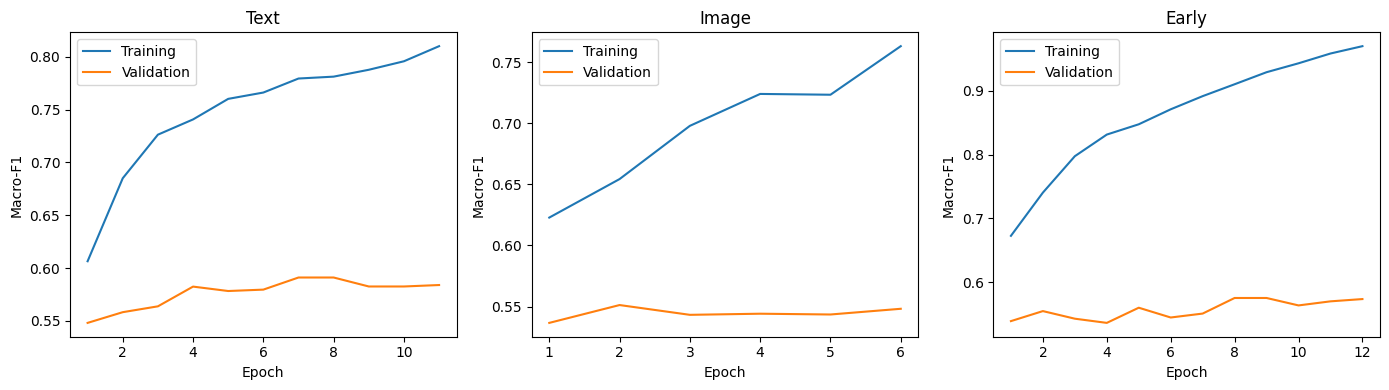

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, model_name in zip(
    axes, ["text", "image", "early"]
):
    history_df = pd.DataFrame(
        histories[model_name, SEEDS[0]]
    )

    ax.plot(
        history_df["epoch"],
        history_df["train_macro_f1"],
        label="Training",
    )

    ax.plot(
        history_df["epoch"],
        history_df["dev_macro_f1"],
        label="Validation",
    )

    ax.set_title(model_name.capitalize())
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Macro-F1")
    ax.legend()

plt.tight_layout()
plt.savefig(
    OUT / "learning_curves.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

In [14]:
def calculate_metrics(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    both_classes = len(np.unique(y_true)) == 2

    return {
        "accuracy": accuracy_score(
            y_true, predictions
        ),
        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            labels=[0, 1],
            zero_division=0,
        ),
        "informative_precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "informative_recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "auroc": (
            roc_auc_score(y_true, probabilities)
            if both_classes else np.nan
        ),
        "average_precision": (
            average_precision_score(
                y_true, probabilities
            )
            if both_classes else np.nan
        ),
    }


test_idx = split_indices["test"]
test_labels = labels[test_idx]

test_probabilities = {}
result_records = []
event_records = []

for seed in SEEDS:
    head_latencies = {}

    for model_name, array in features.items():
        test_array = array[test_idx]
        model = models[model_name, seed]

        # Warm up before measuring.
        predict_probabilities(model, test_array[:16])

        synchronize()
        start_time = time.perf_counter()

        probabilities = predict_probabilities(
            model, test_array
        )

        synchronize()
        inference_seconds = (
            time.perf_counter() - start_time
        )

        milliseconds_per_record = (
            inference_seconds / len(test_labels) * 1000
        )

        head_latencies[model_name] = (
            milliseconds_per_record
        )

        test_probabilities[model_name, seed] = (
            probabilities
        )

        result_records.append({
            "model": model_name,
            "seed": seed,
            **calculate_metrics(
                test_labels, probabilities
            ),
            "head_train_seconds": training_times[
                model_name, seed
            ],
            "head_ms_per_record": milliseconds_per_record,
        })

    start_time = time.perf_counter()

    late_probabilities = (
        fusion_weights[seed]
        * test_probabilities["text", seed]
        + (1 - fusion_weights[seed])
        * test_probabilities["image", seed]
    )

    combination_seconds = (
        time.perf_counter() - start_time
    )

    test_probabilities["late", seed] = (
        late_probabilities
    )

    result_records.append({
        "model": "late",
        "seed": seed,
        **calculate_metrics(
            test_labels, late_probabilities
        ),
        "head_train_seconds": (
            training_times["text", seed]
            + training_times["image", seed]
        ),
        "head_ms_per_record": (
            head_latencies["text"]
            + head_latencies["image"]
            + combination_seconds
            / len(test_labels) * 1000
        ),
    })

    test_events = work.iloc[test_idx][
        "event"
    ].to_numpy()

    for model_name in ["text", "image", "early", "late"]:
        for event in sorted(np.unique(test_events)):
            mask = test_events == event

            event_records.append({
                "model": model_name,
                "seed": seed,
                "event": event,
                "n": int(mask.sum()),
                **calculate_metrics(
                    test_labels[mask],
                    test_probabilities[
                        model_name, seed
                    ][mask],
                ),
            })

results = pd.DataFrame(result_records)
event_results = pd.DataFrame(event_records)

results.to_csv(
    OUT / "test_metrics.csv", index=False
)

event_results.to_csv(
    OUT / "event_metrics.csv", index=False
)

summary_columns = [
    "macro_f1",
    "accuracy",
    "informative_precision",
    "informative_recall",
    "auroc",
    "head_train_seconds",
    "head_ms_per_record",
]

summary = results.groupby("model")[
    summary_columns
].agg(["mean", "std"])

summary.to_csv(OUT / "test_summary.csv")

display(summary.round(4))

# Majority class is determined from training labels.
majority_class = int(
    np.bincount(
        labels[split_indices["train"]]
    ).argmax()
)

majority_metrics = calculate_metrics(
    test_labels,
    np.full(
        len(test_labels),
        float(majority_class),
    ),
)

print("Majority baseline:")
print(majority_metrics)

macro_f1     accuracy     informative_precision     informative_recall  \
          mean std     mean std                  mean std               mean   
model                                                                          
early   0.7221 NaN   0.7433 NaN                0.7688 NaN             0.8315   
image   0.5592 NaN   0.5700 NaN                0.6687 NaN             0.5924   
late    0.6717 NaN   0.6867 NaN                0.7500 NaN             0.7337   
text    0.6937 NaN   0.7133 NaN                0.7552 NaN             0.7880   

            auroc     head_train_seconds     head_ms_per_record      
      std    mean std               mean std               mean std  
model                                                                
early NaN  0.7768 NaN             0.4158 NaN             0.0018 NaN  
image NaN  0.6297 NaN             0.1955 NaN             0.0014 NaN  
late  NaN  0.7525 NaN             0.7097 NaN             0.0034 NaN  
text  NaN  0.7216 NaN             0.5142 NaN             0.0020 NaN

Majority baseline:
{'accuracy': 0.6133333333333333, 'macro_f1': 0.38016528925619836, 'informative_precision': 0.6133333333333333, 'informative_recall': 1.0, 'auroc': np.float64(0.5), 'average_precision': np.float64(0.6133333333333333)}


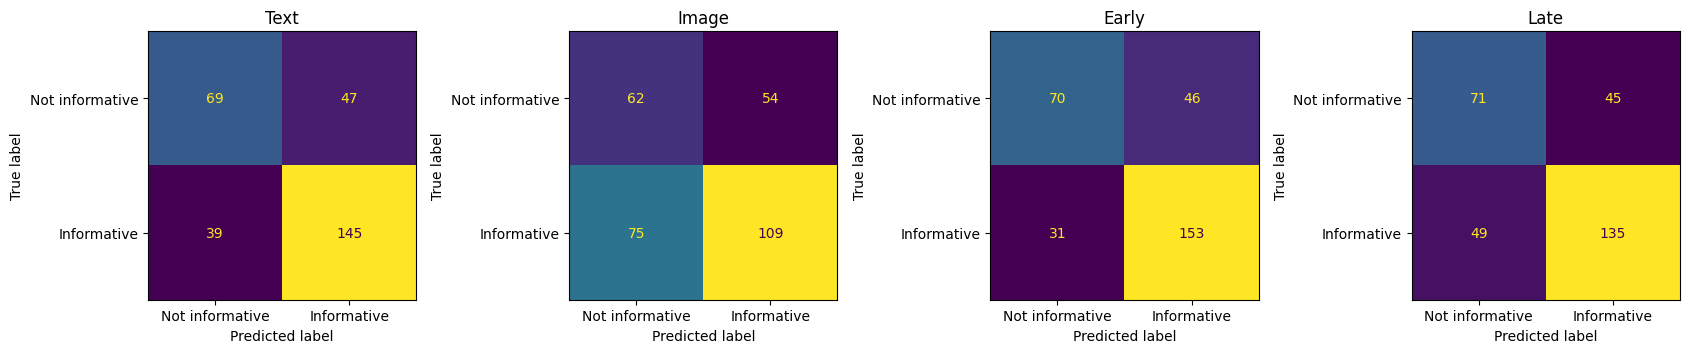

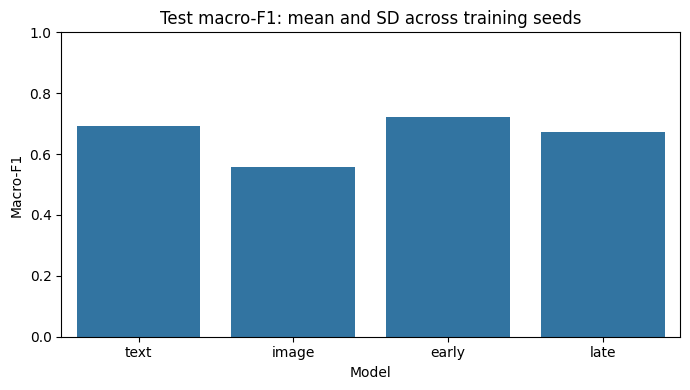

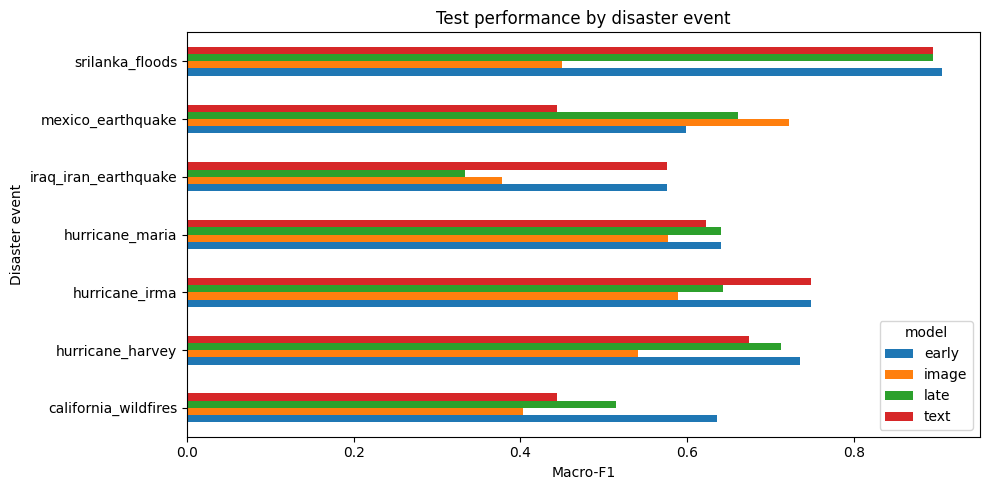

Test records per event:


,count
event,
hurricane_irma,80
hurricane_maria,78
hurricane_harvey,67
california_wildfires,35
mexico_earthquake,15
iraq_iran_earthquake,14
srilanka_floods,11


In [15]:
# Confusion matrices for the first pre-specified seed.
fig, axes = plt.subplots(1, 4, figsize=(17, 4))

for ax, model_name in zip(
    axes, ["text", "image", "early", "late"]
):
    predictions = (
        test_probabilities[
            model_name, SEEDS[0]
        ] >= 0.5
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        test_labels,
        predictions,
        labels=[0, 1],
        display_labels=[
            "Not informative", "Informative"
        ],
        ax=ax,
        colorbar=False,
    )

    ax.set_title(model_name.capitalize())

plt.tight_layout()
plt.savefig(
    OUT / "confusion_matrices.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


# Overall comparison.
fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(
    data=results,
    x="model",
    y="macro_f1",
    errorbar="sd",
    ax=ax,
)

ax.set_ylim(0, 1)
ax.set_title(
    "Test macro-F1: mean and SD across training seeds"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")

plt.tight_layout()
plt.savefig(
    OUT / "model_comparison.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


# Per-event comparison.
event_table = (
    event_results.groupby(["event", "model"])[
        "macro_f1"
    ].mean().unstack()
)

ax = event_table.plot.barh(figsize=(10, 5))

ax.set_xlabel("Macro-F1")
ax.set_ylabel("Disaster event")
ax.set_title("Test performance by disaster event")

plt.tight_layout()
plt.savefig(
    OUT / "event_performance.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Test records per event:")
display(
    work.iloc[test_idx]["event"].value_counts()
)

In [16]:
best_unimodal = (
    selection_table[
        selection_table["model"].isin(
            ["text", "image"]
        )
    ]
    .groupby("model")["dev_macro_f1"]
    .mean()
    .idxmax()
)

chosen_prob = test_probabilities[
    selected_model, SEEDS[0]
]

baseline_prob = test_probabilities[
    best_unimodal, SEEDS[0]
]

test_groups = work.iloc[test_idx][
    "group"
].to_numpy()

unique_groups = np.unique(test_groups)

group_positions = {
    group: np.flatnonzero(test_groups == group)
    for group in unique_groups
}

rng = np.random.default_rng(42)
bootstrap_differences = []

for _ in tqdm(range(1000), desc="Group bootstrap"):
    sampled_groups = rng.choice(
        unique_groups,
        size=len(unique_groups),
        replace=True,
    )

    sampled_rows = np.concatenate([
        group_positions[group]
        for group in sampled_groups
    ])

    chosen_f1 = f1_score(
        test_labels[sampled_rows],
        chosen_prob[sampled_rows] >= 0.5,
        average="macro",
        labels=[0, 1],
        zero_division=0,
    )

    baseline_f1 = f1_score(
        test_labels[sampled_rows],
        baseline_prob[sampled_rows] >= 0.5,
        average="macro",
        labels=[0, 1],
        zero_division=0,
    )

    bootstrap_differences.append(
        chosen_f1 - baseline_f1
    )

comparison = {
    "selected_model": selected_model,
    "unimodal_baseline": best_unimodal,
    "seed": SEEDS[0],
    "macro_f1_difference": (
        calculate_metrics(
            test_labels, chosen_prob
        )["macro_f1"]
        - calculate_metrics(
            test_labels, baseline_prob
        )["macro_f1"]
    ),
    "bootstrap_95_percentile_interval": (
        np.quantile(
            bootstrap_differences,
            [0.025, 0.975],
        ).tolist()
    ),
}

print(json.dumps(comparison, indent=2))

(OUT / "paired_bootstrap.json").write_text(
    json.dumps(comparison, indent=2)
)

Group bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

{
  "selected_model": "late",
  "unimodal_baseline": "text",
  "seed": 42,
  "macro_f1_difference": -0.021947433651815174,
  "bootstrap_95_percentile_interval": [
    -0.07426769725395942,
    0.028934611468290634
  ]
}


219